# 00 · Práctica de PyTorch: de los tensores al bucle de entrenamiento

Seis ejercicios cortos para aprender a escribir sin mirar el **núcleo** de `01_cnn_baseline.ipynb`. Cada ejercicio tiene:

1. el enunciado y unas pistas;
2. **tu celda**, con la plantilla mínima;
3. una celda **✅ Comprobación** con `assert`s que te dicen si está bien. No la modifiques: ejecútala después de tu celda.

| # | Ejercicio | Qué aprendes | Equivale en `01_cnn_baseline` a |
|---|---|---|---|
| 1 | Formas y parámetros | cómo cambian las dimensiones capa a capa | §2.1 (resumen del modelo) |
| 2 | Tu CNN | `nn.Module`, `__init__` / `forward` | §2 (`MarsCNN`) |
| 3 | Sobreajustar un batch | los 4 pasos del entrenamiento | núcleo de `run_epoch` |
| 4 | Bucle mínimo con datos reales | `Dataset`, `DataLoader`, train/val | §1 + §4 simplificados |
| 5 | Evaluación, checkpoint, early stopping y scheduler | `fit` completo | `fit` |
| 6 | Medir el entrenamiento | sincronización CUDA, memoria, throughput | §3 y §8 |

Kernel **mars** en WSL. Si te atascas, pide la solución del ejercicio concreto.

## Chuleta: funciones que vas a necesitar

### Tensores y dispositivo
| Función | Para qué sirve |
|---|---|
| `torch.randn(8, 3, 224, 224)` | Tensor aleatorio normal(0, 1) con esa forma. Sirve para probar modelos sin datos. |
| `torch.randint(0, 5, (8,))` | Enteros aleatorios en [0, 5): etiquetas de prueba. |
| `x.shape` | Forma del tensor. Las imágenes van en `(B, C, H, W)`: batch, canales, alto y ancho. |
| `torch.cuda.is_available()` / `torch.device("cuda")` | Comprobar la GPU y elegir el dispositivo. |
| `x.to(device)` / `model.to(device)` | Mover datos o modelo a la GPU. **Datos y modelo tienen que estar en el mismo dispositivo.** |
| `x.item()` | Convierte un tensor de un elemento en un número de Python (por ejemplo, la pérdida). |
| `logits.argmax(dim=1)` | Índice del valor máximo por fila, es decir, la clase predicha. |
| `x.numel()` | Número total de elementos. Con `p.numel()` se cuentan los parámetros. |

### Capas (`torch.nn`)
| Capa | Qué hace | Parámetros |
|---|---|---|
| `nn.Conv2d(c_in, c_out, kernel_size=3, stride=1, padding=1, bias=True)` | Desliza `c_out` filtros de `c_in×k×k` por la imagen; cada filtro da un mapa de salida. | `c_out·c_in·k·k` (+ `c_out` de bias) |
| `nn.BatchNorm2d(c)` | Normaliza cada canal a media 0 y var 1 sobre el batch, y reescala con γ, β aprendidos. | `2·c` |
| `nn.ReLU()` | `max(0, x)`: no linealidad. | 0 |
| `nn.MaxPool2d(2)` | Máximo en ventanas de 2×2: reduce H y W a la mitad. | 0 |
| `nn.AdaptiveAvgPool2d(1)` | Media de cada canal entero (*Global Average Pooling*): `(C, H, W) → (C, 1, 1)`. Hace al modelo independiente del tamaño de entrada. | 0 |
| `nn.Flatten()` | `(B, C, 1, 1) → (B, C)`. | 0 |
| `nn.Dropout(p)` | En entrenamiento pone a 0 una fracción `p` de las activaciones; en evaluación no hace nada. | 0 |
| `nn.Linear(in, out)` | Capa densa: `y = xWᵀ + b`. | `in·out + out` |
| `nn.Sequential(a, b, c)` | Encadena capas: `c(b(a(x)))`. | — |

**Fórmula del tamaño de salida** (convolución y pooling): `out = ⌊(in + 2·padding − kernel) / stride⌋ + 1`

### Definir un modelo
```python
class MiModelo(nn.Module):
    def __init__(self, ...):
        super().__init__()          # obligatorio, siempre lo primero
        self.capa = nn.Linear(...)  # las capas se crean aquí
    def forward(self, x):           # y se usan aquí
        return self.capa(x)
```
| Método | Para qué sirve |
|---|---|
| `model.parameters()` | Iterador de todos los pesos entrenables. Se pasa al optimizador. |
| `model.train()` / `model.eval()` | Cambian el comportamiento de **BatchNorm** (estadísticas del batch o acumuladas) y **Dropout** (activo o apagado). |
| `model.modules()` | Recorre todas las capas, incluidas las anidadas. |
| `model.state_dict()` / `model.load_state_dict(sd)` | Obtener o cargar los pesos (un diccionario de tensores). |
| `torch.save(obj, ruta)` / `torch.load(ruta, weights_only=True)` | Guardar y cargar checkpoints. |

### Entrenamiento
| Función | Para qué sirve |
|---|---|
| `nn.CrossEntropyLoss()` | Pérdida de clasificación. Recibe **logits** (sin softmax) y etiquetas **enteras** `(B,)`. |
| `torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)` | Optimizador del artículo. |
| `optimizer.zero_grad()` | Borra los gradientes del paso anterior. PyTorch los **acumula** si no lo haces. |
| `loss.backward()` | Calcula los gradientes de la pérdida respecto a cada parámetro (*backpropagation*). |
| `optimizer.step()` | Actualiza los pesos usando esos gradientes. |
| `with torch.no_grad():` | Desactiva el cálculo de gradientes. Se usa al evaluar: ahorra memoria y tiempo. |
| `torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=5)` | Divide el LR por 2 si la métrica no mejora en `patience` épocas. Se llama con `scheduler.step(métrica)`. |
| `optimizer.param_groups[0]["lr"]` | LR actual. |

### Datos
| Función | Para qué sirve |
|---|---|
| `torchvision.datasets.ImageFolder(ruta, transform=...)` | Dataset a partir de carpetas `ruta/<clase>/*.jpg`. Tiene `.classes` y `.class_to_idx`. |
| `T.Compose([...])` | Encadena transformaciones (`from torchvision.transforms import v2 as T`). |
| `T.Resize((h, w))` | Redimensiona. |
| `T.ToImage()` + `T.ToDtype(torch.float32, scale=True)` | Pasan de PIL a un tensor float en [0, 1]. |
| `T.Normalize(mean, std)` | `(x − mean) / std` por canal. |
| `T.RandomHorizontalFlip()` | Aumentación: volteo aleatorio. |
| `DataLoader(ds, batch_size=32, shuffle=True, num_workers=4)` | Agrupa muestras en batches. `shuffle=True` solo en train. |
| `TensorDataset(x, y)` | Dataset a partir de tensores ya creados. Útil para pruebas. |

### Medición
| Función | Para qué sirve |
|---|---|
| `time.perf_counter()` | Reloj de alta precisión, en segundos. |
| `torch.cuda.synchronize()` | Espera a que la GPU termine. **La GPU trabaja de forma asíncrona**: sin esto se mide solo lo que tarda Python en *encargar* el trabajo. |
| `torch.cuda.reset_peak_memory_stats()` / `torch.cuda.max_memory_allocated()` | Reiniciar y leer la memoria pico de la GPU, en bytes. |

## 0. Configuración (ya está hecha, solo ejecútala)

In [1]:
import random, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import v2 as T

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
DATA = ROOT / "data"
assert DATA.exists(), "Abre el notebook desde la raíz del repo"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.15.0+cu132


## Ejercicio 1 · Formas y parámetros

**Sin ejecutar nada**, predice con la fórmula `out = ⌊(in + 2p − k) / s⌋ + 1` la forma de salida `(C, H, W)` de cada capa aplicada a una entrada `(3, 224, 224)`, o a `(32, 224, 224)` en las de pooling. Predice también cuántos parámetros tiene cada capa.

Después ejecuta la comprobación: te dirá cuáles has fallado y el valor real.

**Pistas:**
- `padding=1` con `kernel_size=3` y `stride=1` mantiene el tamaño. Por eso se usa tanto.
- Un filtro de una `Conv2d` mira **todos** los canales de entrada a la vez: tiene `c_in × k × k` pesos.

In [2]:
# Tuplas (C, H, W) sin la dimensión del batch
shape_conv = (32,224,224)        # nn.Conv2d(3, 32, kernel_size=3, padding=1)            sobre (3, 224, 224)
shape_conv_nopad = (32,222,222)  # nn.Conv2d(3, 32, kernel_size=3, padding=0)            sobre (3, 224, 224)
shape_conv_s2 = (32,112,112)    # nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1)  sobre (3, 224, 224)
shape_pool = (32,112,112)        # nn.MaxPool2d(2)                                       sobre (32, 224, 224)
shape_gap = (32,1,1)        # nn.AdaptiveAvgPool2d(1)                               sobre (32, 224, 224)

n_params_conv = 896   # parámetros de nn.Conv2d(3, 32, kernel_size=3)   (con bias)
n_params_conv_nb = 18432  # parámetros de nn.Conv2d(32, 64, kernel_size=3, bias=False)
n_params_bn = 128       # parámetros entrenables de nn.BatchNorm2d(64)
n_params_fc = 1285       # parámetros de nn.Linear(256, 5)

In [3]:
# ✅ Comprobación ejercicio 1 (no modificar)
x3, x32 = torch.zeros(1, 3, 224, 224), torch.zeros(1, 32, 224, 224)
nparams = lambda m: sum(p.numel() for p in m.parameters())
checks = {
    "shape_conv": (shape_conv, tuple(nn.Conv2d(3, 32, 3, padding=1)(x3).shape[1:])),
    "shape_conv_nopad": (shape_conv_nopad, tuple(nn.Conv2d(3, 32, 3, padding=0)(x3).shape[1:])),
    "shape_conv_s2": (shape_conv_s2, tuple(nn.Conv2d(3, 32, 3, stride=2, padding=1)(x3).shape[1:])),
    "shape_pool": (shape_pool, tuple(nn.MaxPool2d(2)(x32).shape[1:])),
    "shape_gap": (shape_gap, tuple(nn.AdaptiveAvgPool2d(1)(x32).shape[1:])),
    "n_params_conv": (n_params_conv, nparams(nn.Conv2d(3, 32, 3))),
    "n_params_conv_nb": (n_params_conv_nb, nparams(nn.Conv2d(32, 64, 3, bias=False))),
    "n_params_bn": (n_params_bn, nparams(nn.BatchNorm2d(64))),
    "n_params_fc": (n_params_fc, nparams(nn.Linear(256, 5))),
}
fails = [f"  {k}: tú {mine} | real {real}" for k, (mine, real) in checks.items()
         if (tuple(mine) if isinstance(mine, (tuple, list)) else mine) != real]
assert not fails, "Revisa:\n" + "\n".join(fails)
print("✔ Ejercicio 1 correcto")

✔ Ejercicio 1 correcto


**Para pensar:** ¿por qué `shape_conv_s2` y `shape_pool` dan lo mismo? Las dos reducen a la mitad, pero una **aprende** cómo hacerlo y la otra no.

El primero hace una convolución que debido al stride hace que las convoluciones se calculen saltandose una por lo que el output el la mitad, el segundo lo que hace es de 4 pixeles se queda con el valor maximo

## Ejercicio 2 · Tu CNN

Escribe:

1. **`conv_block(c_in, c_out)`**, que devuelve un `nn.Sequential` con:
   `Conv2d(c_in→c_out, 3×3, padding=1, bias=False) → BatchNorm2d → ReLU → Conv2d(c_out→c_out, 3×3, padding=1, bias=False) → BatchNorm2d → ReLU → MaxPool2d(2)`
2. **`class MiCNN(nn.Module)`** con `__init__(self, n_classes=5, widths=(32, 64, 128, 256, 256), dropout=0.3)`:
   - un `conv_block` por cada valor de `widths`, encadenados (la salida de uno es la entrada del siguiente; el primero recibe 3 canales);
   - `AdaptiveAvgPool2d(1) → Flatten → Dropout(dropout) → Linear(último width → n_classes)`;
   - `forward(x)` devuelve los **logits** `(B, n_classes)`.

**Pistas:**
- Para construir los bloques en un bucle: crea una lista, añade los bloques con `.append(...)` y conviértela con `nn.Sequential(*lista)`. Lleva en una variable cuántos canales salen del bloque anterior.
- ¿Por qué `bias=False`? La BatchNorm de después resta la media, así que el bias se anularía. Su β hace ese papel.

In [4]:
def conv_block(c_in, c_out):
    return nn.Sequential(
    nn.Conv2d(c_in, c_out,kernel_size=3,padding=1, bias=False),
    nn.BatchNorm2d(c_out),
    nn.ReLU(inplace=True),
    nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(c_out),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(2),
    )


class MiCNN(nn.Module):
    def __init__(self, n_classes=5, widths=(32, 64, 128, 256, 256), dropout=0.3):
        super().__init__()
        blocks, c_in = [], 3
        for w in widths:
            blocks.append(conv_block(c_in,w))
            c_in = w

        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.head(x)
        return x

In [5]:
# ✅ Comprobación ejercicio 2 (no modificar)
blk = conv_block(3, 32)
assert isinstance(blk, nn.Module), "conv_block debe devolver un nn.Sequential"
assert blk(torch.zeros(2, 3, 64, 64)).shape == (2, 32, 32, 32), "conv_block(3, 32) sobre (2,3,64,64) debe dar (2,32,32,32)"
assert sum(isinstance(m, nn.Conv2d) for m in blk.modules()) == 2, "conv_block debe tener 2 Conv2d"
assert all(m.bias is None for m in blk.modules() if isinstance(m, nn.Conv2d)), "Las Conv2d van con bias=False"

m = MiCNN()
out = m(torch.zeros(4, 3, 224, 224))
assert out.shape == (4, 5), f"La salida debe ser (4, 5) y es {tuple(out.shape)}"
assert m(torch.zeros(4, 3, 128, 128)).shape == (4, 5), "Con GAP debe funcionar con cualquier tamaño de entrada"
counts = {t.__name__: sum(isinstance(x, t) for x in m.modules()) for t in (nn.Conv2d, nn.BatchNorm2d, nn.MaxPool2d, nn.Dropout, nn.Linear)}
assert counts == {"Conv2d": 10, "BatchNorm2d": 10, "MaxPool2d": 5, "Dropout": 1, "Linear": 1}, f"Capas: {counts}"
n = sum(p.numel() for p in m.parameters())
assert n == 2_355_173, f"Parámetros: {n:,} (esperado 2,355,173)"
assert MiCNN(n_classes=3, widths=(8, 16))(torch.zeros(1, 3, 32, 32)).shape == (1, 3), "Usa n_classes y widths, no valores fijos"
print(f"✔ Ejercicio 2 correcto: {n:,} parámetros")

✔ Ejercicio 2 correcto: 2,355,173 parámetros


## Ejercicio 3 · Sobreajustar un solo batch (prueba de cordura)

Un modelo correcto tiene que ser capaz de **memorizar** 8 ejemplos, aunque sean ruido con etiquetas aleatorias. Si la pérdida no baja casi a 0, hay un bug en el modelo o en el bucle. Esta prueba se hace siempre antes de entrenar de verdad.

Con `x_fixed` e `y_fixed` (ya creados abajo):
1. crea `model3 = MiCNN().to(device)`, el criterio `nn.CrossEntropyLoss()` y `Adam(lr=1e-3)`;
2. pon el modelo en modo entrenamiento;
3. haz **100 pasos** con el mismo batch: *forward → loss → zero_grad → backward → step*;
4. guarda la pérdida de cada paso en la lista `losses`, como número de Python, no como tensor.

In [6]:
set_seed(0)
x_fixed = torch.randn(8, 3, 64, 64, device=device)
y_fixed = torch.randint(0, 5, (8,), device=device)

In [7]:
losses = []
model3 = MiCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model3.parameters(),lr=1e-3)

for step in range(100):
    logits = model3(x_fixed) 
    loss = criterion(logits,y_fixed)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

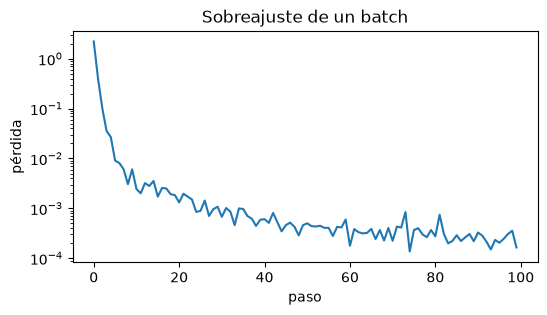

✔ Ejercicio 3 correcto: 2.223 → 0.0002


In [8]:
# ✅ Comprobación ejercicio 3 (no modificar)
assert len(losses) == 100, f"Debe haber 100 pérdidas y hay {len(losses)}"
assert all(isinstance(l, float) for l in losses), "Guarda loss.item(), no el tensor"
assert losses[0] > 1.0, "La pérdida inicial debería estar cerca de ln(5) ≈ 1.61"
assert losses[-1] < 0.1, f"La pérdida final es {losses[-1]:.3f}: no memoriza. ¿Falta zero_grad, step o model.train()?"
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.yscale("log")
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.title("Sobreajuste de un batch"); plt.show()
print(f"✔ Ejercicio 3 correcto: {losses[0]:.3f} → {losses[-1]:.4f}")

**Para pensar:**
- ¿Por qué la pérdida inicial es ≈ ln(5)? Pista: con pesos aleatorios, la red reparte la probabilidad a partes iguales entre 5 clases.
- Quita `optimizer.zero_grad()`, vuelve a ejecutar y mira qué pasa con la curva.

## Ejercicio 4 · Bucle mínimo con datos reales

Usa la partición **original** de `data/` (train/val) con `ImageFolder`; para practicar basta. Las imágenes van a **128×128** para que sea rápido.

1. `tf = T.Compose([...])` con `Resize((128, 128))`, `ToImage`, `ToDtype(float32, scale=True)` y `Normalize` de ImageNet (`[0.485, 0.456, 0.406]` / `[0.229, 0.224, 0.225]`).
2. `train_ds` y `val_ds` con `torchvision.datasets.ImageFolder(DATA / "train", transform=tf)` (igual para val).
3. `train_loader` (batch 32, `shuffle=True`, `num_workers=4`) y `val_loader` (batch 64, `shuffle=False`, `num_workers=4`).
4. `model4 = MiCNN().to(device)`, `CrossEntropyLoss`, `Adam(lr=1e-3)`.
5. **5 épocas.** En cada una:
   - entrena con `model4.train()` y acumula la pérdida media de train;
   - evalúa con `model4.eval()` y `torch.no_grad()` para calcular la val acc;
   - añade a `history4` un diccionario `{"epoch", "train_loss", "val_acc"}` e imprímelo.

**Pistas:**
- Pérdida media de una época: suma `loss.item() * y.size(0)` en cada batch y divide al final por `len(train_ds)`.
- Aciertos de un batch: `(logits.argmax(1) == y).sum().item()`.

In [70]:
history4 = []
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

tf = T.Compose([
    T.ToImage(),
    T.Resize((128,128)),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = torchvision.datasets.ImageFolder(DATA / "train", transform=tf)
val_ds =  torchvision.datasets.ImageFolder(DATA / "val", transform=tf)


train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4)

model4 = MiCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model4.parameters(),lr=1e-3)

for epoch in range(5):
    model4.train()
    perdida = 0
    for x, y in train_loader:
        x,y = x.to(device), y.to(device)
        logits = model4(x)
        loss = criterion(logits, y)
        perdida += loss.item()*y.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    perdida_media = perdida/len(train_ds)
    print(perdida_media)
    model4.eval()
    val_acc = 0
    with torch.no_grad(): 
        for x,y in val_loader:
            x,y = x.to(device), y.to(device)
            logits = model4(x)
            val_acc += (logits.argmax(1) == y).sum().item() 
    history4.append({"epoch":epoch, "train_loss":perdida_media, "val_acc":val_acc/len(val_ds)})



1.1526445215276544
0.9177105267146353
0.7684397550488593
0.6978429572304736
0.6579232279290544


In [71]:
# ✅ Comprobación ejercicio 4 (no modificar)
assert train_ds.classes == ["artifacts", "invalid", "regolith", "rocks", "rover_tracks"], train_ds.classes
assert (len(train_ds), len(val_ds)) == (799, 201), f"Tamaños {len(train_ds)}, {len(val_ds)}"
xb, yb = next(iter(train_loader))
assert xb.shape == (32, 3, 128, 128) and xb.dtype == torch.float32, f"Batch {tuple(xb.shape)} {xb.dtype}"
assert -1.5 < xb.mean() < 1.5, "¿Has normalizado?"
assert len(history4) == 5 and set(history4[0]) >= {"epoch", "train_loss", "val_acc"}, "history4 debe tener 5 dicts con epoch, train_loss y val_acc"
assert history4[-1]["train_loss"] < history4[0]["train_loss"], "La pérdida de train no baja"
assert history4[-1]["val_acc"] > 0.35, f"val_acc {history4[-1]['val_acc']:.2f}: por encima del azar (0.2) pero demasiado baja"
print(f"✔ Ejercicio 4 correcto: val acc final {history4[-1]['val_acc']:.3f}")

✔ Ejercicio 4 correcto: val acc final 0.657


**Para pensar:** si quitas `model4.eval()` al validar, ¿cambia la accuracy? ¿Por qué? Pista: BatchNorm y Dropout.

si quito el eval el modelo seguira el modo entrenamiento y cambiaran los pesos segun los resultados de la validación

## Ejercicio 5 · Evaluación, checkpoint, early stopping y scheduler

### 5a · `evaluate(model, loader, criterion)`
Devuelve una tupla `(loss_media, accuracy)` sobre todo el `loader`:
- `model.eval()` y `torch.no_grad()`;
- la pérdida media **ponderada por el tamaño de cada batch** (el último batch puede ser más pequeño);
- mueve los datos al `device` del modelo.

In [39]:
def evaluate(model, loader, criterion):
    model.eval()
    
    val_acc = 0
    perdida= 0
    n = 0
    with torch.no_grad():
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            logits = model(x)
            batch_size = len(x)
            loss = criterion(logits, y)
            perdida += loss.item()*batch_size 
            val_acc += (logits.argmax(1) == y).sum().item()
            n += batch_size
        perdida_media = perdida/ n
    
    return(perdida_media,val_acc/n)

In [40]:
# ✅ Comprobación ejercicio 5a (no modificar)
set_seed(1)
xe, ye = torch.randn(50, 4), torch.randint(0, 3, (50,))
lin = nn.Linear(4, 3).to(device)
loader_e = DataLoader(TensorDataset(xe, ye), batch_size=16)          # batches de 16, 16, 16 y 2
with torch.no_grad():
    logits_e = lin(xe.to(device))
    exp_loss = F.cross_entropy(logits_e, ye.to(device)).item()
    exp_acc = (logits_e.argmax(1).cpu() == ye).float().mean().item()
res = evaluate(lin, loader_e, nn.CrossEntropyLoss())
assert isinstance(res, tuple) and len(res) == 2, "Devuelve (loss, acc)"
assert abs(res[0] - exp_loss) < 1e-5, f"loss {res[0]:.5f} ≠ {exp_loss:.5f}: ¿ponderas por el tamaño del batch?"
assert abs(res[1] - exp_acc) < 1e-6, f"acc {res[1]:.4f} ≠ {exp_acc:.4f}"
assert all(p.grad is None for p in lin.parameters()), "No debe calcular gradientes: usa torch.no_grad()"
print("✔ Ejercicio 5a correcto")

✔ Ejercicio 5a correcto


### 5b · `fit(...)`
```python
fit(model, train_loader, val_loader, epochs, es_patience, ckpt_path, lr=1e-3, sched_patience=5) -> list[dict]
```
En cada época:
1. entrena una pasada (Adam con `lr` y `weight_decay=1e-4`, `CrossEntropyLoss`) y calcula la `train_loss` media;
2. `val_loss, val_acc = evaluate(...)`;
3. guarda en el historial `{"epoch", "train_loss", "val_loss", "val_acc", "lr"}`, con el LR **antes** de llamar al scheduler;
4. `scheduler.step(val_acc)`, con un `ReduceLROnPlateau(mode="max", factor=0.5, patience=sched_patience)` como en el artículo;
5. si `val_loss` es la mejor hasta ahora, guarda **`torch.save(model.state_dict(), ckpt_path)`** y pon el contador a 0; si no, súmale 1;
6. si el contador llega a `es_patience`, para (**early stopping**).

Devuelve la lista del historial.

**Pistas:**
- Empieza con `best = float("inf")`.
- El optimizador y el scheduler se crean **dentro** de `fit`, una sola vez, antes del bucle de épocas.

In [37]:
def fit(model, train_loader, val_loader, epochs, es_patience, ckpt_path, lr=1e-3, sched_patience=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max", factor=0.5, patience=sched_patience)

    history = []
    best = float("inf") 
    bad = 0

    for epoch in range(1, epochs+1):
        model.train()
        perdida, val_acc, n = 0, 0, 0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            logits =  model(x)
            batch_size = len(x)
            loss = criterion(logits, y)
            perdida += loss.item()*batch_size 
            n += batch_size
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        perdida_media = perdida / n
        val_loss, val_acc = evaluate(model,val_loader,criterion)

        history.append({"epoch":epoch, "train_loss": perdida_media, "val_loss": val_loss, "val_acc": val_acc, "lr":  optimizer.param_groups[0]["lr"]})

        scheduler.step(val_acc)

        if val_loss < best :
            best = val_loss
            torch.save(model.state_dict(), ckpt_path)
            bad = 0
        else:
            bad +=1
        if bad >= es_patience:
            break
    return history

In [38]:
# ✅ Comprobación ejercicio 5b (no modificar)
# Datos de ruido: no hay nada que aprender, así que val_loss empeora pronto y el early stopping tiene que saltar
set_seed(2)
xn, yn = torch.randn(200, 3, 32, 32), torch.randint(0, 5, (200,))
tl = DataLoader(TensorDataset(xn[:160], yn[:160]), batch_size=16, shuffle=True)
vl = DataLoader(TensorDataset(xn[160:], yn[160:]), batch_size=16)
ckpt_test = Path("_test_ckpt.pt")
set_seed(3)
m5 = MiCNN(widths=(8, 16)).to(device)
hist = fit(m5, tl, vl, epochs=60, es_patience=4, ckpt_path=ckpt_test, sched_patience=1)

assert isinstance(hist, list) and len(hist) > 0, "fit debe devolver una lista de dicts"
assert set(hist[0]) >= {"epoch", "train_loss", "val_loss", "val_acc", "lr"}, f"Claves: {set(hist[0])}"
assert len(hist) < 60, "El early stopping no ha parado el entrenamiento"
best_i = int(np.argmin([h["val_loss"] for h in hist]))
assert len(hist) - 1 - best_i == 4, f"Debe parar 4 épocas después del mínimo (mínimo en época {best_i + 1}, paró en {len(hist)})"
assert hist[0]["lr"] == 1e-3 and min(h["lr"] for h in hist) < 1e-3, "El LR nunca baja: ¿llamas a scheduler.step(val_acc)?"
assert ckpt_test.exists(), "No se ha guardado el checkpoint"
m5b = MiCNN(widths=(8, 16)).to(device)
m5b.load_state_dict(torch.load(ckpt_test, weights_only=True))
vloss, _ = evaluate(m5b, vl, nn.CrossEntropyLoss())
assert abs(vloss - hist[best_i]["val_loss"]) < 1e-4, "El checkpoint guardado no es el de menor val_loss"
ckpt_test.unlink()
print(f"✔ Ejercicio 5b correcto: paró en la época {len(hist)}, mejor época {best_i + 1}, LR final {hist[-1]['lr']:.1e}")

✔ Ejercicio 5b correcto: paró en la época 5, mejor época 1, LR final 5.0e-04


**Bonus:** entrena `MiCNN` con tu `fit` sobre los loaders del ejercicio 4 (por ejemplo `epochs=40, es_patience=8`) y dibuja `train_loss`, `val_loss` y `val_acc` frente a la época.

In [72]:
m5 = MiCNN().to(device)

hist = fit(m5, train_loader, val_loader, epochs=40, es_patience=8, ckpt_path=ckpt_test, sched_patience=5)

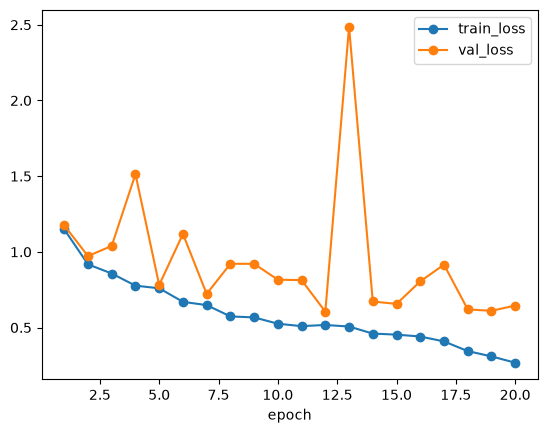

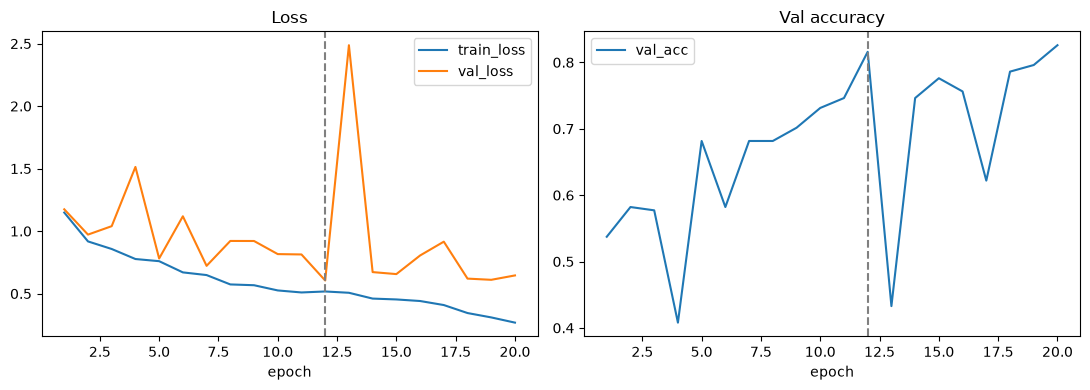

In [73]:
import pandas as pd

df = pd.DataFrame(hist)          # cada dict es una fila y cada clave una columna
df.plot(x="epoch", y=["train_loss", "val_loss"], marker="o")
plt.show()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
df.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax1, title="Loss")
df.plot(x="epoch", y="val_acc", ax=ax2, title="Val accuracy")

best = df["val_loss"].idxmin()                     # fila de la mejor época (la del checkpoint)
for ax in (ax1, ax2):
    ax.axvline(df.loc[best, "epoch"], ls="--", c="gray")
plt.tight_layout()
plt.show()

## Ejercicio 6 · Medir un paso de entrenamiento

Escribe `measure_train_step(model, batch_size, img_size=224, steps=20, warmup=5)`, que devuelve `{"img_per_s", "ms_per_step", "peak_mem_MB"}`:

1. crea datos sintéticos **directamente en la GPU**: `torch.randn(batch_size, 3, img_size, img_size, device=device)` y etiquetas con `randint`. Así no se mide la carga de datos;
2. un optimizador Adam y `model.train()`;
3. `warmup` pasos sin medir: la primera vez, CUDA y cuDNN inicializan cosas y tardan más;
4. `torch.cuda.reset_peak_memory_stats()`, `torch.cuda.synchronize()` y `t0 = time.perf_counter()`;
5. `steps` pasos de entrenamiento;
6. `torch.cuda.synchronize()` y después el tiempo transcurrido;
7. calcula `img_per_s = batch_size * steps / dt`, `ms_per_step` y `peak_mem_MB = torch.cuda.max_memory_allocated() / 1024**2`.

In [57]:

def measure_train_step(model, batch_size, img_size=224, steps=20, warmup=5):
    x = torch.randn(batch_size,3, img_size, img_size, device=device)
    y = torch.randint(0, 5, (batch_size,), device=device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    model.train()
    def step():
        logits =  model(x)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    for _ in range(warmup): step()

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(steps): step()
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0

    return {"img_per_s": batch_size * steps / dt, "ms_per_step": 1000 * dt/steps, "peak_mem_MB": torch.cuda.max_memory_allocated()/1024**2}

In [58]:
# ✅ Comprobación ejercicio 6 (no modificar)
assert device.type == "cuda", "Este ejercicio necesita la GPU"
res8 = measure_train_step(MiCNN().to(device), 8)
res32 = measure_train_step(MiCNN().to(device), 32)
for r in (res8, res32):
    assert set(r) >= {"img_per_s", "ms_per_step", "peak_mem_MB"}, f"Claves: {set(r)}"
    assert all(v > 0 for v in r.values())
assert res32["peak_mem_MB"] > 2 * res8["peak_mem_MB"], "Con un batch 4× mayor la memoria debería crecer bastante"
assert abs(res8["img_per_s"] - 8 * 1000 / res8["ms_per_step"]) / res8["img_per_s"] < 0.01, "img_per_s y ms_per_step no cuadran"
for bs, r in [(8, res8), (32, res32)]:
    print(f"batch {bs:3d}: {r['img_per_s']:6.0f} img/s | {r['ms_per_step']:6.1f} ms/paso | {r['peak_mem_MB']:6.0f} MB")
print("✔ Ejercicio 6 correcto")

batch   8:    224 img/s |   35.6 ms/paso |    690 MB
batch  32:    235 img/s |  135.9 ms/paso |   2034 MB
✔ Ejercicio 6 correcto


**Para pensar:** copia tu función, quita los dos `torch.cuda.synchronize()` y compara los `ms_per_step`. ¿Por qué sale distinto? ¿Cuál de las dos medidas es la buena?

In [59]:

def measure_train_step(model, batch_size, img_size=224, steps=20, warmup=5):
    x = torch.randn(batch_size,3, img_size, img_size, device=device)
    y = torch.randint(0, 5, (batch_size,), device=device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    model.train()
    def step():
        logits =  model(x)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    for _ in range(warmup): step()

    torch.cuda.reset_peak_memory_stats()
    #torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(steps): step()
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0

    return {"img_per_s": batch_size * steps / dt, "ms_per_step": 1000 * dt/steps, "peak_mem_MB": torch.cuda.max_memory_allocated()/1024**2}

In [60]:
# ✅ Comprobación ejercicio 6 (no modificar)
assert device.type == "cuda", "Este ejercicio necesita la GPU"
res8 = measure_train_step(MiCNN().to(device), 8)
res32 = measure_train_step(MiCNN().to(device), 32)
for r in (res8, res32):
    assert set(r) >= {"img_per_s", "ms_per_step", "peak_mem_MB"}, f"Claves: {set(r)}"
    assert all(v > 0 for v in r.values())
assert res32["peak_mem_MB"] > 2 * res8["peak_mem_MB"], "Con un batch 4× mayor la memoria debería crecer bastante"
assert abs(res8["img_per_s"] - 8 * 1000 / res8["ms_per_step"]) / res8["img_per_s"] < 0.01, "img_per_s y ms_per_step no cuadran"
for bs, r in [(8, res8), (32, res32)]:
    print(f"batch {bs:3d}: {r['img_per_s']:6.0f} img/s | {r['ms_per_step']:6.1f} ms/paso | {r['peak_mem_MB']:6.0f} MB")
print("✔ Ejercicio 6 correcto")

batch   8:    153 img/s |   52.4 ms/paso |    690 MB
batch  32:    192 img/s |  166.6 ms/paso |   2034 MB
✔ Ejercicio 6 correcto


si quito el synchronize se aumenta los ms por paso, entiendo que es porque tarda mas en sincronizarse y aumenta el tiempo por step

## ¿Y ahora?

Si has superado las 6 comprobaciones, ya sabes escribir el núcleo de `01_cnn_baseline.ipynb`. Lo que añade ese notebook encima es:

| En `01` | Qué añade sobre lo que has hecho |
|---|---|
| `CachedImageDataset` | Un `Dataset` propio (`__len__` / `__getitem__`) que guarda las imágenes en RAM para no leer el disco cada época |
| `train_tf` | Aumentaciones aleatorias, solo en train |
| `run_epoch` | Tu bucle, más la medida de tiempos (datos frente a cómputo) y AMP opcional |
| `fit` | Lo mismo que tu 5b, más el registro de métricas del proceso |
| `GPUMonitor` | Un hilo que lee la utilización de la GPU mientras entrenas |
| §7 | `sklearn` para F1 y la matriz de confusión |

Siguiente reto, sin mirar: escribe un `Dataset` propio que lea `splits/split_v1.csv` y devuelva `(imagen, etiqueta)`.